# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

In [2]:
import json

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

# TODO:
1. Wikipedia harvest - Run as is for now, try to understand why it crushes near the end. **---------> DONE!**
2. Extract tables:
    - length between 3 to 10 **---------> DONE!**
    - table is square and parsed normally (no merged cells) **---------> DONE!**
    - full table **---------> DONE!**
    - remove some columns with no relevant data (empty or by keywords) **---------> DONE!**
3. Add to table extraction text titles and relevant paragraphs for the context. **---------> DONE!**
4. Cluster titles to remove similar options + take only one table per page. **---------> DONE!**
5. Create groups - all the table, try to see what is the main entity - return the column name, if they don't have one, discard the table and return 'None'. **---------> DONE!**
6. Create Questions
    - strategy injection, sample a subset of strategies in a shuffled order, if not possible than discard table.
    - make a function to extract the answer per question strategy --> create GT answer.
    - Add the 'group size' strategy.
    - constract the data samples.

### Havest Wikipedia pages with tables:

In [91]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiHarvester
# Initialize Wikipedia harvester
harvester = WikiHarvester()
# Run Phase 1 - Harvesting titles based on keywords
harvester.run_complete_harvest()
# Run Phase 2 - Filtering pages for tables
await harvester.filter_pages_async()

Harvesting Pages By Keywords:   0%|          | 0/233 [00:00<?, ?keyword/s]


TOTAL UNIQUE TITLES COLLECTED: 167913



Method,Keyword,Count
Prefix,List of cities,1537
Prefix,List of countries,1278
Prefix,List of towns,501
Prefix,List of villages,483
Prefix,List of districts,375
Prefix,List of municipalities,1021
Prefix,List of communes,194
Prefix,List of counties,259
Prefix,List of provinces,84
Prefix,List of territories,22


Filtering Pages with Tables:   0%|          | 0/167913 [00:00<?, ?page/s]


TOTAL PAGES WITH TABLES COLLECTED: 62306



In [93]:
save_json("table_titles", harvester.valid_titles)

In [3]:
table_titles = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/table_titles.json")

### Parse and filter Wikipedia tables:

In [ ]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

In [4]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)

Pre-processing: cluster similar pages and discard similarities ---> 6426 pages discarded.


Extracting Tables:   0%|          | 0/55880 [00:00<?, ?Page/s]

Starting Extraction: 55880 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 37946 OUT OF 55880 (67.9%)


In [5]:
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

In [70]:
from knowledge_maze.create_dataset.create_questions.table_processing import TablePostProcessor

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

Selecting Best Tables: 100%|█████████████████████████████████████████████████| 17442/17442 [00:00<00:00, 717648.13it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      126924
Dropped (Single Col):      577
Dropped (Bad Headers):     9813
Dropped (Cell too long):   2682
Short tables found:        38679
Unique source pages:       17442
Final sampled (1/page):    17442
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


═════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Rank,Division,Gold,Silver,Bronze,Total
0,1,New England,4,5,1,10
1,2,Alaska,2,5,3,10
2,3,Intermountain,3,1,1,5
3,4,Pacific Northwest,2,0,2,4
4,5,Rocky Mountain,0,1,2,3
5,6,Far West*,0,0,1,1
6,7,Great Lakes,0,0,1,1
7,8,Midwest,0,0,1,1
8,9,High Plains,0,0,0,0
9,10,Mid-Atlantic,0,0,0,0



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of phobias > Psychological conditions > G
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Phobia,Condition
0,Galeophobia,fear of sharks
1,Gamophobia,fear of marriage
2,Gelotophobia,fear of being laughed at
3,Gephyrophobia,fear of bridges
4,"Genophobia , coitophobia",fear of sexual intercourse
5,Genuphobia,fear of knees or the act of kneeling
6,Gerascophobia,fear of growing old or aging
7,Gerontophobia,"fear of growing old, or a hatred or fear of th..."
8,Globophobia,fear of balloons
9,Glossophobia,fear of speaking in public or of trying to speak



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of members of the parliament of Malta, 2017–2022 > List by office
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Office,Officeholder,Year,Political party
0,President of Malta,Marie-Louise Coleiro Preca,2014–2019,Partit Laburista
1,President of Malta,George Vella,2019–present,Partit Laburista
2,Prime Minister of Malta,Joseph Muscat,2013–2020,Partit Laburista
3,Prime Minister of Malta,Robert Abela,2020–present,Partit Laburista
4,Leader of Opposition,Adrian Delia,2017–2020,Partit Nazzjonalista
5,Leader of Opposition,Bernard Grech,2020–present,Partit Nazzjonalista
6,Speaker,Anġlu Farrugia,2013–present,Partit Laburista



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of adjectivals and demonyms of astronomical bodies > Moons (Saturn)
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Name,"Adjective, demonym"
0,Dione,Dionean
1,Enceladus,"Enceladean, Enceladan"
2,Hyperion,Hyperionian
3,Iapetus,"Iapetian, Japetian"
4,Mimas,"Mimantean, Mimantian"
5,Rhea,Rhean
6,Tethys,Tethyan
7,Titan,"Titanian / t aɪ ˈ t eɪ n i ə n / , Titanean"


### Create Potential Entity Groups:

In [269]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 100))
await group_constructor.get_groups()

Creating groups based on the Wikipedia tables using LLM...


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/100 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE LLM GROUPING SUMMARY
════════════════════════════════════════════
Total tables scanned:      100
Total groups made:      93
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE Groups ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> Bowl games played by the North Carolina A&T Aggies football team, including wins and losses, from 1943 to 2019.
--> Actors who have received two or more Best Actor aw

,Championship Team of the Week,17 August 2009,Stephen Wright
0,Championship Team of the Week,28 September 2009,Leon Best
1,Championship Player of the Month,3 October 2009,Leon Best
2,Championship Team of the Week,5 October 2009,Sammy Clingan
3,Championship Team of the Week,30 November 2009,Richard Wood
4,Championship Team of the Week,14 December 2009,Freddy Eastwood
5,Championship Team of the Week,22 February 2010,Keiren Westwood
6,Championship Team of the Week,1 March 2010,Sammy Clingan
7,Championship Team of the Week,8 March 2010,Jon Stead
8,Championship Team of the Week,15 March 2010,Michael McIndoe
9,Championship Team of the Week,26 April 2010,Aron Gunnarsson



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> Planet of the Apes > Cast and crew > Crew
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Crew/detail,Original series,Remake,Reboot series
0,Planet of the Apes,Beneath the Planet of the Apes,Escape from the Planet of the Apes,Conquest of the Planet of the Apes
1,1968,1970,1971,1972
2,Director,Franklin J. Schaffner,Ted Post,Don Taylor
3,Producer(s),Arthur P. Jacobs,Arthur P. Jacobs,Arthur P. Jacobs
4,Story by,Michael Wilson and Rod Serling,Paul Dehn and Mort Abrahams,Paul Dehn
5,Screenwriter(s),Michael Wilson and Rod Serling,Paul Dehn,Paul Dehn
6,Composer,Jerry Goldsmith,Leonard Rosenman,Jerry Goldsmith
7,Cinematographer,Leon Shamroy,Milton Krasner,Joseph Biroc
8,Editor(s),Hugh Fowler,Marion Rothman,Marion Rothman


In [270]:
for sample in random.sample(group_constructor.valid_tables, 25):
    print(f"Group name: {sample['Group name']}")
    print(f"Wikipedia page: {sample['Wikipedia page']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Faculties of the University of National and World Economy, including their founding years.
Wikipedia page: https://en.wikipedia.org/wiki/University_of_National_and_World_Economy#Faculties


,Faculty,Year founded
0,Faculty of Finance and Accounting,1920
1,Faculty of Business,1949
2,Faculty of General Economics,1958
3,Faculty of Law,1991 (1920)
4,Faculty of International Economics and Politics,1995 (1975)
5,Faculty of Economics of Infrastructure,1995
6,Faculty of Management and Administration,1995
7,Faculty of Applied Informatics and Statistics,2008




Group name: Diplomatic missions of Chad located in various countries across Asia, including embassies and consulates.
Wikipedia page: https://en.wikipedia.org/wiki/List_of_diplomatic_missions_of_Chad#Current_missions


,Host country,Host city,Mission,Concurrent accreditation
0,China,Beijing,Embassy,Countries : Indonesia
1,India,New Delhi,Embassy,Countries : Afghanistan Bangladesh Nepal Sri L...
2,Kuwait,Kuwait City,Embassy,
3,Qatar,Doha,Embassy,
4,Saudi Arabia,Riyadh,Embassy,Countries : Bahrain
5,Saudi Arabia,Jeddah,Consulate-General,Countries : Bahrain
6,South Korea,Seoul,Consulate,
7,Turkey,Ankara,Embassy,Countries : Azerbaijan
8,United Arab Emirates,Abu Dhabi,Embassy,
9,United Arab Emirates,Dubai,Consulate-General,




Group name: The 10 countries with the largest number of Christians, ranked by their total Christian population.
Wikipedia page: https://en.wikipedia.org/wiki/Christianity_by_country#Lists


...

,Team,Men,Ladies,Pairs,Ice dancing
0,Team Focus,Yuma Kagiyama ( JPN ),Kate Wang ( USA ),Cate Fleming / Jedidah Isbell ( USA ),Sofya Tyutyunina / Alexander Shustitskiy ( RUS )
1,Team Discovery,Nikolaj Memola ( ITA ),Catherine Carle ( CAN ),Apollinariia Panfilova / Dmitry Rylov ( RUS ),Célina Fradji / Jean-Hans Fourneaux ( FRA )
2,Team Courage,Arlet Levandi ( EST ),Ksenia Sinitsyna ( RUS ),Alina Butaeva / Luka Berulava ( GEO ),Utana Yoshida / Shingo Nishiyama ( JPN )
3,Team Determination,Cha Young-hyun ( KOR ),Nella Pelkonen ( FIN ),Brooke McIntosh / Brandon Toste ( CAN ),Katarina Wolfkostin / Jeffrey Chen ( USA )
4,Team Motivation,Andrey Kokura ( UKR ),Alessia Tornaghi ( ITA ),Diana Mukhametzianova / Ilya Mironov ( RUS ),Gina Zehnder / Beda-Leon Sieber ( SUI )
5,Team Future,Matteo Nalbone ( ITA ),Anna Frolova ( RUS ),Wang Yuchen / Huang Yihang ( CHN ),Anna Cherniavska / Oleg Muratov ( UKR )
6,Team Vision,Andrei Mozalev ( RUS ),Regina Schermann ( HUN ),Sofiia Nesterova / Artem Darenskyi ( UKR ),Natalie D'Alessandro / Bruce Waddell ( CAN )
7,Team Hope,Liam Kapeikis ( USA ),Maïa Mazzara ( FRA ),Letizia Roscher / Luis Schuster ( GER ),Miku Makita / Tyler Gunara ( CAN )




Group name: Mayors of Zurich from 1803 to present, including their terms and political parties.
Wikipedia page: https://en.wikipedia.org/wiki/List_of_mayors_of_Zurich#Stadtpräsident(1803_to_present)


,Term,Mayor,Lifespan,Party
0,1890–1909,Hans Konrad Pestalozzi,(1848–1909),
1,1909–1917,Robert Billeter,(1857–1917),FDP/PRD
2,1917–1928,Hans Nägeli,(1865–1945),Demokraten
3,1928–1942,Emil Klöti,(1877–1963),SPS/PSS
4,1942–1944,Ernst Nobs,(1886–1957),SPS/PSS
5,1944–1949,Adolf Lüchinger,(1894–1949),SPS/PSS
6,1949–1966,Emil Landolt,(1895–1995),FDP/PRD
7,1966–1982,Sigmund Widmer,(1919–2003),LdU
8,1982–1990,Thomas Wagner,(born 1943),FDP/PRD
9,1990–2002,Josef Estermann,(born 1947),SPS/PSS




Group name: Racial and ethnic groups in Escondido, California as of the 2020 Census, excluding Latinos from the racial categories.
Wikipedia page: https://en.wikipedia.org/wiki/Escondido,_California#Demographics


,Race / Ethnicity ( NH = Non-Hispanic ),Pop 2000,Pop 2010,Pop 2020,% 2000,% 2010,% 2020
0,White alone (NH),69305,58142,50693,51.89%,40.40%,33.56%
1,Black or African American alone (NH),2734,3046,3267,2.05%,2.12%,2.16%
2,Native American or Alaska Native alone (NH),776,577,479,0.58%,0.40%,0.32%
3,Asian alone (NH),5812,8491,11650,4.35%,5.90%,7.71%
4,Native Hawaiian or Pacific Islander alone (NH),251,306,325,0.19%,0.21%,0.22%
5,Other Race alone (NH),184,201,664,0.14%,0.14%,0.44%
6,Mixed race or Multiracial (NH),2804,2822,5734,2.10%,1.96%,3.80%
7,Hispanic or Latino (any race),51693,70326,78226,38.70%,48.87%,51.79%
8,Total,133559,143911,151038,100.00%,100.00%,100.00%


### Create FanOut Questions out of the Entity Groups:

In [179]:
from knowledge_maze.create_dataset.create_questions.question_generation import QuestionGenerator

question_generator = QuestionGenerator(random.sample(group_constructor.valid_tables, 50))
await question_generator.generate_questions()

Usage cost: 0.0090$ (Estimated: 0.01$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 18.80it/s]


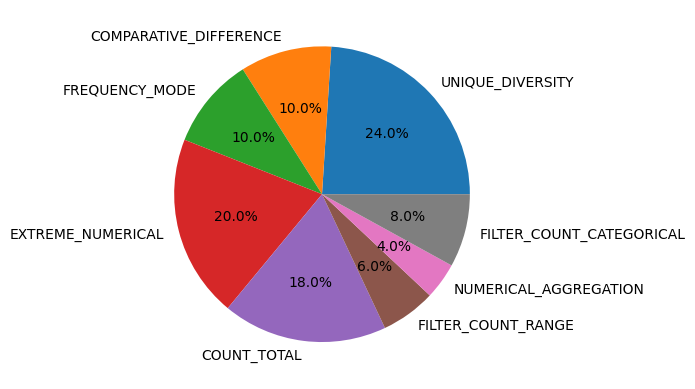

In [180]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_categorical_pie(data):
    counts = Counter(data)
    plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%')

plot_categorical_pie([sample['Strategy'] for sample in question_generator.valid_tables])

In [181]:
for sample in question_generator.valid_tables:
    print(f"Group name: {sample['Group name']}")
    print(f"Strategy: {sample['Strategy']}")
    print(f"Question: {sample['Question']}")
    print(f"Entity column: {sample['Entity column']}")
    print(f"Data column: {sample['Data column']}")
    print(f"Wikipedia page: {sample['Wikipedia page']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Faculties of the University of Arts in Belgrade, including Music Arts, Applied Arts, Dramatic Arts, Fine Arts, and Interdisciplinary Studies.
Strategy: UNIQUE_DIVERSITY
Question: How many different faculties are included in the University of Arts in Belgrade?
Entity column: Faculty
Data column: Faculty
Wikipedia page: https://en.wikipedia.org/wiki/University_of_Arts_in_Belgrade#Faculties


,Faculty,Location,Academic staff,Students
0,Music Arts,Belgrade,204,949
1,Applied Arts,Belgrade,104,820
2,Dramatic Arts,Belgrade,124,653
3,Fine Arts,Belgrade,57,352
4,Interdisciplinary Studies,Belgrade,-,131
5,Total,,489,2905




Group name: Racial and ethnic groups in St. Louis city, Missouri as of the 2020 census.
Strategy: COMPARATIVE_DIFFERENCE
Question: How many more people identified as Black or African American alone (NH) in 2010 compared to 2020 in St. Louis city, Missouri?
Entity column: Race / Ethnicity ( NH = Non-Hispanic )
Data column: Pop 2010
Wikipedia page: https://en.wikipedia.org/wiki/St._Louis#Demographics


,Race / Ethnicity ( NH = Non-Hispanic ),Pop 1980,Pop 1990,Pop 2000,Pop 2010,Pop 2020,% 1980,% 1990,% 2000,% 2010,% 2020
0,White alone (NH),239420,198956,149329,134702,129368,52.84%,50.15%,42.89%,42.19%,42.90%
1,Black or African American alone (NH),204970,187805,177446,156389,128993,45.24%,47.34%,50.96%,48.98%,42.77%
2,Native American or Alaska Native alone (NH),642,874,862,684,614,0.14%,0.22%,0.25%,0.21%,0.20%
3,Asian alone (NH),1696,3616,6820,9233,12205,0.37%,0.91%,1.96%,2.89%,4.05%
4,Native Hawaiian or Pacific Islander alone (NH),x,x,83,62,88,x,x,0.02%,0.02%,0.03%
5,Other race alone (NH),826,310,647,478,1773,0.18%,0.08%,0.19%,0.15%,0.59%
6,Mixed race or Multiracial (NH),x,x,5980,6616,13132,x,x,1.72%,2.07%,4.35%
7,Hispanic or Latino (any race),5531,5124,7022,11130,15405,1.22%,1.29%,2.02%,3.49%,5.11%
8,Total,453085,396685,348189,319294,301578,100.00%,100.00%,100.00%,100.00%,100.00%




Group name: Members of the TKO Board of Directors associated with WWE and Endeavor, including their roles and affiliations.
Strategy: UNIQUE_DIVERSITY
Question: How many different representatives are associated with the TKO Board of Directors?
Entity column: Name
Data column: Representative
Wikipedia page: https://en.wikipedia.org/wiki/List_of_WWE_personnel#Corporate_staff


...

,State,Also claimed by,Head of state,Head of government
0,Abkhazia,Georgia,President – Badra Gunba,President – Badra Gunba
1,Republic of China (Taiwan),People's Republic of China,President – Lai Ching-te,Premier – Cho Jung-tai
2,Kosovo,Serbia,President – Vjosa Osmani,Acting Prime Minister – Albin Kurti
3,Northern Cyprus,Cyprus,President – Tufan Erhürman,Prime Minister – Ünal Üstel
4,Sahrawi Republic,Morocco,General Secretary of the Polisario Front – Bra...,General Secretary of the Polisario Front – Bra...
5,Sahrawi Republic,Morocco,President – Brahim Ghali,Prime Minister – Bouchraya Hammoudi Bayoun
6,Somaliland,Somalia,President – Abdirahman Mohamed Abdullahi,President – Abdirahman Mohamed Abdullahi
7,South Ossetia,Georgia,President – Alan Gagloyev,Prime Minister – Konstantin Dzhussoyev




Group name: Riders from Team Halfords Bikehut who participated in major women's cycling races.
Strategy: FILTER_COUNT_CATEGORICAL
Question: How many riders participated in the European Track Championships?
Entity column: Rider
Data column: Race
Wikipedia page: https://en.wikipedia.org/wiki/Team_Halfords_Bikehut#Results_in_major_races


,Date,Race,Rider,Place
0,28 March,Track Cycling World Championships – Women's te...,Joanna Rowsell Wendy Houvenaghel (with Rebecca...,
1,29 March,Track Cycling World Championships – Women's po...,Lizzie Armitstead,19th
2,30 March,Track Cycling World Championships – Women's sc...,Lizzie Armitstead,7th
3,10 August,Summer Olympics – Women's road race,Nicole Cooke ( GBR ),
4,3 September,European Track Championships – Women's omnium,Ellen van Dijk,
5,September,European Track Championships – Women's under-2...,Lizzie Armitstead Katie Colclough Joanna Rowsell,
6,6 September,European Track Championships – Women's under-2...,Joanna Rowsell,
7,7 September,European Track Championships – Women's under-2...,Lizzie Armitstead Ex aequo with Ellen van Dijk,
8,6 September,European Track Championships – Women's under-2...,Lizzie Armitstead,
9,24 September,Road World Championships – Women's road race,Nicole Cooke ( GBR ),




Group name: The 10 largest employers in the world ranked by the number of employees, including government and private organizations.
Strategy: UNIQUE_DIVERSITY
Question: How many different countries are represented by the 10 largest employers in the world?
Entity column: Employer
Data column: Country
Wikipedia page: https://en.wikipedia.org/wiki/List_of_largest_employers#Largest_employers


,Rank,Employer,Employees (mn),Country
0,1,Ministry of Defence (India),9.26,India
1,2,United States Department of Defense,2.91,United States
2,3,People's Liberation Army,3.15,China
3,4,Walmart,2.30,United States
4,5,Amazon,1.61,United States
5,6,China National Petroleum,1.45,China
6,7,National Health Service,1.38,United Kingdom
7,8,Foxconn,1.29,Taiwan
8,9,Indian Railways,1.21,India
9,10,Tata Group,1.15,India


# Test:

In [250]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables_test.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(random.sample(table_titles, 10000))
validated_tables_test = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables_test.jsonl"))
processor_test = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables_test.jsonl"))
cleaned_data_test = processor_test.process()

Pre-processing: cluster similar pages and discard similarities ---> 355 pages discarded.


Extracting Tables:   0%|          | 0/9645 [00:00<?, ?Page/s]

Starting Extraction: 9645 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 5643 OUT OF 9645 (58.5%)


Filtering & Cleaning:   0%|          | 0/16218 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      16218
Dropped (Single Col):      0
Dropped (Bad Headers):     1319
Dropped (Cell too long):   522
Dropped (Repeat Rows):     302
Short tables found:        7084
Unique source pages:       3046
Final sampled (1/page):    3046
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------

══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Nominations,Film
0,13,Barfi!
1,9,Vicky Donor
2,8,Agneepath
3,8,Gangs of Wasseypur – Part 1
4,5,Cocktail
5,4,Jab Tak Hai Jaan
6,4,Kahaani
7,4,Paan Singh Tomar
8,3,Housefull 2
9,3,OMG – Oh My God!



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
List of earthquakes in 2013 > By death toll
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Rank,Death toll,Magnitude,Location,MMI,Depth (km),Date
0,1,825,7.7,"Pakistan , Balochistan",IX ( Violent ),20.0,September 24
1,2,222,7.1,"Philippines , Central Visayas",IX ( Violent ),19.0,October 15
2,3,216,6.6,"China , Sichuan",VIII ( Severe ),12.0,April 20
3,4,95,5.9,"China , Gansu",VII ( Very strong ),20.0,July 22
4,5,43,6.1,"Indonesia , Sumatra",VIII ( Severe ),10.0,July 2
5,6,40,6.3,"Iran , Bushehr",VIII ( Severe ),10.0,April 9
6,7,35,7.7,"Iran , Sistan and Baluchestan",VII ( Very strong ),82.0,April 16
7,8,22,6.8,"Pakistan , Balochistan",VIII ( Severe ),14.8,September 28
8,9,18,5.6,"Afghanistan , Laghman",V ( Moderate ),62.0,April 24
9,10,13,8.0,Solomon Islands,VIII ( Severe ),29.0,February 6



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Sterling Airlines > Fleet (Sterling Airlines Fleet)
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Aircraft,Total,Passengers,Routes,Notes
0,Boeing 737-500,4,126,Europe,
1,Boeing 737-700,15,148,Europe,
2,Boeing 737-800,7,189,Europe,
3,McDonnell Douglas MD-83,1,165,Europe,operated by FlyExcellent


In [256]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor_test = TableGroupConstructor(cleaned_data_test)
await group_constructor_test.get_groups()

Creating groups based on the Wikipedia tables using LLM...


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/3046 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE LLM GROUPING SUMMARY
════════════════════════════════════════════
Total tables scanned:      3046
Total groups made:      2785
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE Groups ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------


══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> Jewish communities located in Sussex, England, including various congregations and societies.
--> Massacres that occurred at sea, detailing the events, locations, 

,Year,Number of recipients
0,1961,20
1,1962,9
2,1963,7
3,1964,7
4,1965,7 (+ 1 team award)
5,1966,13
6,1967,15
7,1968,7
8,1969,10



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
--> 1982 Metro Manila Film Festival > Winners and nominees > Awards (boldface)
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Best Film,Best Director
0,Himala Moral Haplos,Ishmael Bernal – Himala
1,Best Actor,Best Actress
2,Christopher de Leon – Haplos,Nora Aunor – Himala
3,Best Supporting Actor,Best Supporting Actress
4,Spanky Manikan – Himala,Gigi Dueñas – Himala
5,Best Sound Engineering,Best Cinematography
6,Rolly Ruta – Himala,Sergio Lobo – Himala
7,Best Editing,Best Music
8,"Ike Jarlego, Jr. and Ben Pelayo – Himala",Ernani Cuenco – Ang Panday: Ikatlong Yugto
9,Best Art Direction,Best Screenplay
